# NB3 — Task 2b: Optimizers, Learning Rates & Schedulers
____________________________________________________________________________________________________

In NB2 we chose the **architecture**. In this notebook we keep this architecture fixed and study **how it is trained**:

a. Recap of the optimizers: SGD with momentum, Adam, AdamW

b. Training helpers

c. **Grid search**: 3 optimizers × 3 initial learning rates (1e-2, 1e-3, 1e-4) = 9 trainings with a constant learning rate

d. **Learning rate schedulers**: with the best (optimizer, learning rate) pair, we compare no scheduler, StepLR, CosineAnnealingLR and OneCycleLR

e. Comparative table and plots

f. Best training recipe on the test set + checkpoint loading

Everything else is fixed: same data (no augmentation), same architecture, same number of epochs, same seed.

## 0. Setup

In [1]:
import os
import json
import time
import random

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

ON_KAGGLE = os.path.exists("/kaggle/input")

def find_path(name, search_roots):
    # walk the search folders and return the first file / folder called `name`
    for search_root in search_roots:
        for root, dirs, files in os.walk(search_root):
            if name in dirs or name in files:
                return os.path.join(root, name)
    return None

SEARCH_ROOTS = ["/kaggle/input"] if ON_KAGGLE else ["..", "../.."]
DATA_ROOT = find_path("EuroSAT_RGB", SEARCH_ROOTS)
SPLITS_FILE = find_path("splits.json", SEARCH_ROOTS)

OUT_DIR = "/kaggle/working" if ON_KAGGLE else "."
CKPT_DIR = os.path.join(OUT_DIR, "checkpoints")
RES_DIR = os.path.join(OUT_DIR, "results")
os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)

NUM_WORKERS = 4 if ON_KAGGLE else 0

print("DATA_ROOT  :", DATA_ROOT)
print("SPLITS_FILE:", SPLITS_FILE)

Using device: cuda:0
DATA_ROOT  : /kaggle/input/datasets/waseemalastal/eurosat-rgb-dataset/EuroSAT_RGB
SPLITS_FILE: /kaggle/input/notebooks/emilioyared/aide500-nb0-setup-data-run-1010-1100/splits.json


In [2]:
with open(SPLITS_FILE) as f:
    splits = json.load(f)

classes = splits["classes"]
num_classes = len(classes)
MEAN, STD = splits["mean"], splits["std"]

# no data augmentation in this notebook (studied in NB4)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])

dataset = torchvision.datasets.ImageFolder(root=DATA_ROOT, transform=transform)
trainset = Subset(dataset, splits["train"])
valset = Subset(dataset, splits["val"])
testset = Subset(dataset, splits["test"])
print("train: %d | val: %d | test: %d" % (len(trainset), len(valset), len(testset)))

BATCH_SIZE = 64
trainloader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
valloader = DataLoader(valset, batch_size=256, shuffle=False, num_workers=NUM_WORKERS)
testloader = DataLoader(testset, batch_size=256, shuffle=False, num_workers=NUM_WORKERS)

train: 18900 | val: 4050 | test: 4050


**The architecture: best configuration of NB2**

We read the configuration saved by NB2 (`NB2_best_config.json`) and use the same `ConfigNet` class.

In [3]:
class ConfigNet(nn.Module):
    def __init__(self, n_blocks=3, kernel_size=3, padding="same", downsample="pool", use_bn=False, n_fc=2, num_classes=10):
        super(ConfigNet, self).__init__()
        channels = [3] + [min(32 * 2 ** i, 256) for i in range(n_blocks)]  # e.g. n_blocks=3 -> [3, 32, 64, 128]
        p = kernel_size // 2 if padding == "same" else 0
        s = 2 if downsample == "stride" else 1

        blocks = []
        h = 64  # input images are 64x64
        for i in range(n_blocks):
            layers = []
            # with BatchNorm, the conv bias is useless (BN subtracts the mean and adds its own bias beta)
            layers.append(nn.Conv2d(channels[i], channels[i + 1], kernel_size, stride=s, padding=p, bias=not use_bn))
            h = (h + 2 * p - kernel_size) // s + 1           # size after the convolution
            if use_bn:
                layers.append(nn.BatchNorm2d(channels[i + 1]))
            layers.append(nn.ReLU())
            if downsample == "pool":
                layers.append(nn.MaxPool2d(2, 2))
                h = (h - 2) // 2 + 1                         # size after the pooling
            blocks.append(nn.Sequential(*layers))
        self.features = nn.Sequential(*blocks)

        assert h >= 1, "the feature maps disappear (size %d): too many blocks for this padding / kernel" % h
        self.flat_features = channels[-1] * h * h            # number of inputs of the first fc layer
        self.out_size = h

        # fully connected layers: 1 -> [flat, 10] | 2 -> [flat, 256, 10] | 3 -> [flat, 256, 128, 10]
        fc_sizes = [self.flat_features] + [256, 128][:n_fc - 1] + [num_classes]
        fc_layers = []
        for i in range(n_fc):
            fc_layers.append(nn.Linear(fc_sizes[i], fc_sizes[i + 1]))
            if i < n_fc - 1:                                 # no ReLU after the last layer (we want raw scores)
                fc_layers.append(nn.ReLU())
        self.classifier = nn.Sequential(*fc_layers)

    def forward(self, x):
        x = self.features(x)                     # [B, C, h, h]
        x = x.view(-1, self.flat_features)       # [B, C*h*h] flatten
        x = self.classifier(x)                   # [B, 10]
        return x


# check: the default configuration is exactly the baseline of NB1
net = ConfigNet()
print(net)
print("last feature maps: %dx%d | flat features: %d" % (net.out_size, net.out_size, net.flat_features))
print("parameters:", sum(p.numel() for p in net.parameters()))

ConfigNet(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (classifier): Sequential(
    (0): Linear(in_features=8192, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=10, bias=True)
  )
)
last feature maps: 8x8 | flat features: 8192
parameters: 2193226


In [4]:
BEST_ARCH_FILE = find_path("NB2_best_config.json", SEARCH_ROOTS)
if BEST_ARCH_FILE is not None:
    with open(BEST_ARCH_FILE) as f:
        ARCH = json.load(f)["config"]
    print("architecture from NB2 (%s):" % BEST_ARCH_FILE, ARCH)
else:
    # fallback if NB2 results are not available: baseline + Batch Normalization
    ARCH = dict(n_blocks=3, kernel_size=3, padding="same", downsample="pool", use_bn=True, n_fc=2)
    print("NB2_best_config.json not found -> default architecture:", ARCH)

net = ConfigNet(**ARCH)
print("parameters:", sum(p.numel() for p in net.parameters()))

architecture from NB2 (/kaggle/input/notebooks/emilioyared/aide500-nb2-architecture-variations-run-1010-1129/results/NB2_best_config.json): {'n_blocks': 5, 'n_fc': 2, 'kernel_size': 3, 'padding': 'same', 'downsample': 'pool', 'use_bn': True}
parameters: 1244202


## a. Optimizers

All the optimizers use the gradient $g_t = \nabla_w L$ computed by `loss.backward()`, but they use it differently in `optimizer.step()`.

**SGD with momentum** (as in the labs). The update keeps a "velocity" $v$, an exponential average of the past gradients:

$$v_t = \mu \, v_{t-1} + g_t, \qquad w_t = w_{t-1} - \eta \, v_t \qquad (\mu = 0.9)$$

Like a ball rolling down the loss surface: it accelerates in directions where the gradients agree and smooths out the oscillations.

**Adam** (adaptive moments). It keeps the average of the gradients ($m$, 1st moment) **and** of the squared gradients ($v$, 2nd moment), and divides by $\sqrt{v}$:

$$m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t, \quad v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2, \quad w_t = w_{t-1} - \eta \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}$$

($\hat m, \hat v$: bias-corrected averages). Each weight gets its **own effective learning rate**: weights with large gradients take smaller steps.

**AdamW** = Adam with **decoupled weight decay**. Weight decay pulls the weights towards 0 (regularization). In Adam, weight decay is added to the gradient ($g_t + \lambda w$) and is then divided by $\sqrt{v}$, which weakens it for weights with large gradients. AdamW instead applies it directly to the weights, outside of the adaptive step:

$$w_t = w_{t-1} - \eta \left( \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon} + \lambda w_{t-1} \right)$$

We use the usual settings of each optimizer:

| Optimizer | Settings |
|---|---|
| SGD | momentum = 0.9, weight decay = 5e-4 |
| Adam | betas = (0.9, 0.999), no weight decay (PyTorch default) |
| AdamW | betas = (0.9, 0.999), weight decay = 0.01 (PyTorch default) |

In [5]:
def make_optimizer(name, params, lr):
    if name == "SGD":
        return optim.SGD(params, lr=lr, momentum=0.9, weight_decay=5e-4)
    if name == "Adam":
        return optim.Adam(params, lr=lr)
    if name == "AdamW":
        return optim.AdamW(params, lr=lr, weight_decay=0.01)
    raise ValueError(name)

## b. Training helpers

Same functions as before, with one difference: `train_one_epoch` can receive a `batch_scheduler`, a scheduler that must be updated **after every mini-batch** (OneCycleLR, see section d). The other schedulers are updated once per **epoch**.

In [6]:
def train_one_epoch(net, loader, criterion, optimizer, batch_scheduler=None):
    net.train()
    running_loss, correct, total = 0.0, 0, 0
    for i, data in enumerate(loader, 0):
        inputs, labels = data[0].to(device), data[1].to(device)

        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        if batch_scheduler is not None:
            batch_scheduler.step()  # OneCycleLR: new learning rate after every mini-batch

        running_loss += loss.item() * labels.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, 100.0 * correct / total

In [7]:
def evaluate(net, loader, criterion):
    net.eval()
    running_loss, total = 0.0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for data in loader:
            images, labels = data[0].to(device), data[1].to(device)
            outputs = net(images)
            running_loss += criterion(outputs, labels).item() * labels.size(0)
            _, predicted = torch.max(outputs, 1)
            all_preds.append(predicted.cpu())
            all_labels.append(labels.cpu())
            total += labels.size(0)
    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()
    acc = 100.0 * (all_preds == all_labels).mean()
    per_class_acc = [100.0 * (all_preds[all_labels == c] == c).mean() for c in range(num_classes)]
    return running_loss / total, acc, per_class_acc, all_preds, all_labels


def measure_latency(net, n_runs=100):
    net.eval()
    x = torch.randn(1, 3, 64, 64).to(device)
    with torch.no_grad():
        for _ in range(10):  # warm-up
            net(x)
        if device.type == "cuda": torch.cuda.synchronize()  # wait for the GPU to finish before reading the time
        start = time.time()
        for _ in range(n_runs):
            net(x)
        if device.type == "cuda": torch.cuda.synchronize()
    return (time.time() - start) / n_runs * 1000  # milliseconds per image

**`run_experiment`**: trains the architecture with a given optimizer, learning rate and scheduler. At every epoch we also record the learning rate used (`optimizer.param_groups[0]["lr"]`), to plot the schedules.

In [8]:
n_epochs = 25
criterion = nn.CrossEntropyLoss()

all_histories = {}
all_summaries = {}
all_recipes = {}


def make_scheduler(name, optimizer, lr):
    # returns (epoch_scheduler, batch_scheduler): only one of them is used
    if name == "none":
        return None, None
    if name == "StepLR":
        # divide the learning rate by 10 every 10 epochs
        return optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1), None
    if name == "Cosine":
        # lr follows half a cosine from lr to ~0 over the n_epochs epochs
        return optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs), None
    if name == "OneCycle":
        # warm-up from lr/25 to max_lr during the first 30% of the steps, then decrease to ~0
        return None, optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, epochs=n_epochs, steps_per_epoch=len(trainloader))
    raise ValueError(name)


def run_experiment(name, opt_name, lr, sched_name="none"):
    set_seed(SEED)
    net = ConfigNet(**ARCH).to(device)
    optimizer = make_optimizer(opt_name, net.parameters(), lr)
    epoch_scheduler, batch_scheduler = make_scheduler(sched_name, optimizer, lr)
    ckpt_path = os.path.join(CKPT_DIR, "NB3_%s.pth" % name)
    print('===== %s | optimizer %s | lr %g | scheduler %s =====' % (name, opt_name, lr, sched_name))

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_per_class_acc": [], "epoch_time": [], "lr": []}
    best_val_acc = 0.0
    for epoch in range(n_epochs):
        history["lr"].append(optimizer.param_groups[0]["lr"])  # learning rate at the start of this epoch
        start = time.time()
        train_loss, train_acc = train_one_epoch(net, trainloader, criterion, optimizer, batch_scheduler)
        val_loss, val_acc, val_per_class_acc, _, _ = evaluate(net, valloader, criterion)
        if epoch_scheduler is not None:
            epoch_scheduler.step()  # StepLR / Cosine: new learning rate after every epoch
        epoch_time = time.time() - start

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_per_class_acc"].append(val_per_class_acc)
        history["epoch_time"].append(epoch_time)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(net.state_dict(), ckpt_path)

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print('[epoch %2d] lr: %.2e | train loss: %.3f | train acc: %.2f %% | val loss: %.3f | val acc: %.2f %% | %.1f s' %
                  (epoch + 1, history["lr"][-1], train_loss, train_acc, val_loss, val_acc, epoch_time))

    best_epoch = int(np.argmax(history["val_acc"]))
    # convergence speed: first epoch where the validation accuracy reaches 90 %
    reached = [e + 1 for e, a in enumerate(history["val_acc"]) if a >= 90.0]
    summary = {
        "name": name, "optimizer": opt_name, "lr": lr, "scheduler": sched_name,
        "best_val_acc": best_val_acc,
        "best_epoch": best_epoch + 1,
        "final_val_acc": history["val_acc"][-1],
        "gen_gap": history["train_acc"][best_epoch] - history["val_acc"][best_epoch],
        "epochs_to_90": reached[0] if reached else None,
        "train_time_s": sum(history["epoch_time"]),
    }
    print('-> best val acc: %.2f %% (epoch %d) | final val acc: %.2f %% | epochs to 90%%: %s' %
          (best_val_acc, best_epoch + 1, summary["final_val_acc"], summary["epochs_to_90"]))

    all_histories[name] = history
    all_summaries[name] = summary
    all_recipes[name] = {"optimizer": opt_name, "lr": lr, "scheduler": sched_name}
    with open(os.path.join(RES_DIR, "NB3_%s_history.json" % name), "w") as f:
        json.dump(history, f)
    return summary

## c. Grid search: optimizer × initial learning rate

9 trainings with a **constant** learning rate (no scheduler).

What we expect:
- a learning rate that is **too large** makes the loss oscillate or diverge (the steps jump over the minima);
- a learning rate that is **too small** converges very slowly;
- Adam / AdamW usually prefer smaller learning rates (~1e-3) than SGD (~1e-2), because their steps are already normalized by $\sqrt{v}$.

In [9]:
OPTIMIZERS = ["SGD", "Adam", "AdamW"]
LRS = [1e-2, 1e-3, 1e-4]

for opt_name in OPTIMIZERS:
    for lr in LRS:
        run_experiment("%s_lr%g" % (opt_name, lr), opt_name, lr)

===== SGD_lr0.01 | optimizer SGD | lr 0.01 | scheduler none =====
[epoch  1] lr: 1.00e-02 | train loss: 0.905 | train acc: 67.81 % | val loss: 1.153 | val acc: 63.43 % | 161.7 s
[epoch  5] lr: 1.00e-02 | train loss: 0.289 | train acc: 89.84 % | val loss: 0.632 | val acc: 81.65 % | 13.8 s
[epoch 10] lr: 1.00e-02 | train loss: 0.150 | train acc: 94.71 % | val loss: 0.269 | val acc: 91.43 % | 14.5 s
[epoch 15] lr: 1.00e-02 | train loss: 0.079 | train acc: 97.19 % | val loss: 0.229 | val acc: 93.04 % | 13.1 s
[epoch 20] lr: 1.00e-02 | train loss: 0.043 | train acc: 98.60 % | val loss: 0.269 | val acc: 92.05 % | 13.5 s
[epoch 25] lr: 1.00e-02 | train loss: 0.034 | train acc: 98.98 % | val loss: 0.236 | val acc: 93.16 % | 14.1 s
-> best val acc: 93.28 % (epoch 24) | final val acc: 93.16 % | epochs to 90%: 10
===== SGD_lr0.001 | optimizer SGD | lr 0.001 | scheduler none =====
[epoch  1] lr: 1.00e-03 | train loss: 0.985 | train acc: 66.88 % | val loss: 0.856 | val acc: 68.59 % | 13.9 s
[epoch 

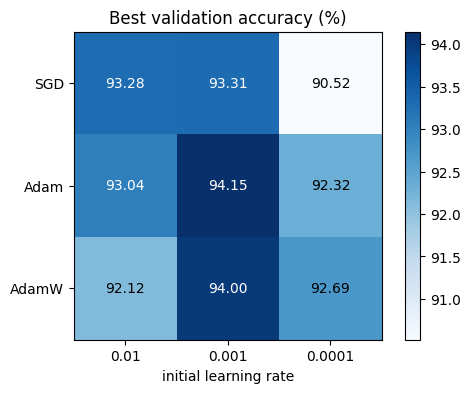

In [10]:
# heatmap of the best validation accuracy of the grid
grid = np.array([[all_summaries["%s_lr%g" % (o, lr)]["best_val_acc"] for lr in LRS] for o in OPTIMIZERS])

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(grid, cmap="Blues")
ax.set_xticks(range(len(LRS))); ax.set_xticklabels(["%g" % lr for lr in LRS])
ax.set_yticks(range(len(OPTIMIZERS))); ax.set_yticklabels(OPTIMIZERS)
ax.set_xlabel("initial learning rate"); ax.set_title("Best validation accuracy (%)")
for i in range(len(OPTIMIZERS)):
    for j in range(len(LRS)):
        ax.text(j, i, "%.2f" % grid[i, j], ha="center", va="center", color="white" if grid[i, j] > grid.mean() else "black")
plt.colorbar(im)
plt.show()

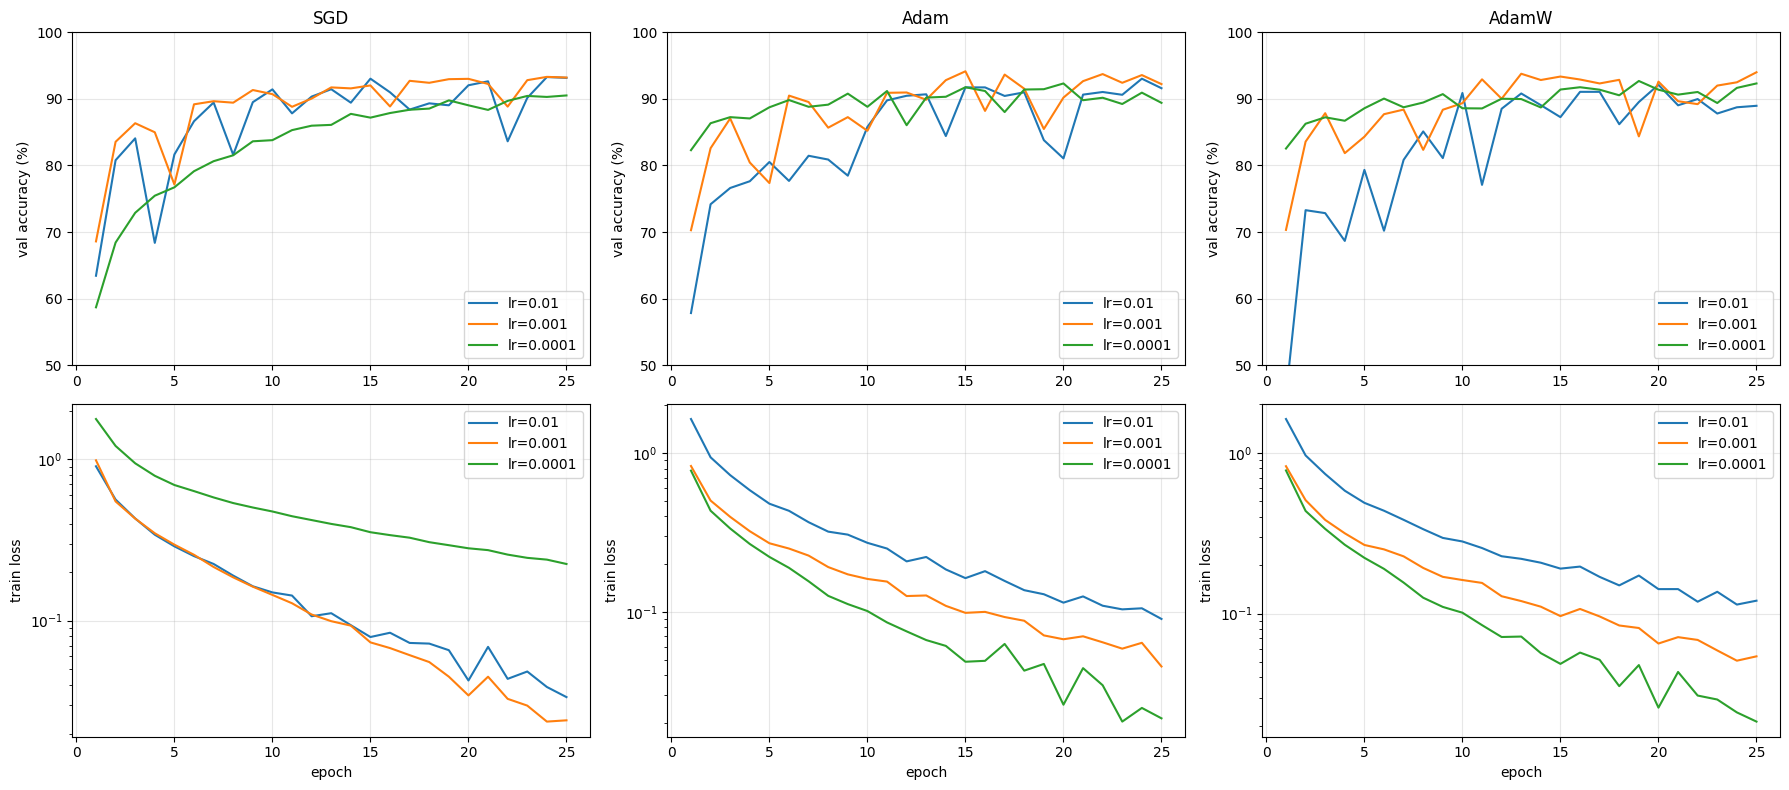

In [11]:
# validation curves of the grid: one plot per optimizer
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
epochs = range(1, n_epochs + 1)
for col, o in enumerate(OPTIMIZERS):
    for lr in LRS:
        h = all_histories["%s_lr%g" % (o, lr)]
        axes[0, col].plot(epochs, h["val_acc"], label="lr=%g" % lr)
        axes[1, col].plot(epochs, h["train_loss"], label="lr=%g" % lr)
    axes[0, col].set_title(o); axes[0, col].set_ylabel("val accuracy (%)"); axes[0, col].set_ylim(50, 100)
    axes[1, col].set_ylabel("train loss"); axes[1, col].set_xlabel("epoch"); axes[1, col].set_yscale("log")
    for r in range(2):
        axes[r, col].legend(); axes[r, col].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## d. Learning rate schedulers

A scheduler changes the learning rate during training. The idea: **large steps at the beginning** (explore, go fast towards a good region), **small steps at the end** (settle precisely in a minimum).

| Scheduler | Rule | Updated |
|---|---|---|
| none | constant lr | — |
| StepLR | lr × 0.1 every 10 epochs | every epoch |
| CosineAnnealingLR | $\eta_t = \frac{\eta_0}{2}\left(1 + \cos\frac{\pi t}{T}\right)$: smooth decrease from $\eta_0$ to 0 | every epoch |
| OneCycleLR | warm-up: lr increases from $\eta_0/25$ to $\eta_0$ (first 30% of the steps), then decreases to ~0 | **every mini-batch** |

We use the best (optimizer, learning rate) pair of the grid search.

In [12]:
best_grid = max(all_summaries.keys(), key=lambda n: all_summaries[n]["best_val_acc"])
BEST_OPT, BEST_LR = all_summaries[best_grid]["optimizer"], all_summaries[best_grid]["lr"]
print("best pair of the grid search: %s with lr=%g (best val acc %.2f %%)" % (BEST_OPT, BEST_LR, all_summaries[best_grid]["best_val_acc"]))

# the "none" scheduler run is the grid search run itself
SCHED_RUNS = {"none": best_grid}
for sched_name in ["StepLR", "Cosine", "OneCycle"]:
    name = "%s_lr%g_%s" % (BEST_OPT, BEST_LR, sched_name)
    run_experiment(name, BEST_OPT, BEST_LR, sched_name)
    SCHED_RUNS[sched_name] = name

best pair of the grid search: Adam with lr=0.001 (best val acc 94.15 %)
===== Adam_lr0.001_StepLR | optimizer Adam | lr 0.001 | scheduler StepLR =====
[epoch  1] lr: 1.00e-03 | train loss: 0.828 | train acc: 70.25 % | val loss: 0.851 | val acc: 70.40 % | 13.4 s
[epoch  5] lr: 1.00e-03 | train loss: 0.272 | train acc: 90.52 % | val loss: 0.536 | val acc: 82.86 % | 13.0 s
[epoch 10] lr: 1.00e-03 | train loss: 0.165 | train acc: 94.21 % | val loss: 0.695 | val acc: 81.60 % | 15.7 s
[epoch 15] lr: 1.00e-04 | train loss: 0.047 | train acc: 98.36 % | val loss: 0.155 | val acc: 95.33 % | 12.7 s
[epoch 20] lr: 1.00e-04 | train loss: 0.032 | train acc: 98.93 % | val loss: 0.163 | val acc: 95.46 % | 14.2 s
[epoch 25] lr: 1.00e-05 | train loss: 0.023 | train acc: 99.30 % | val loss: 0.157 | val acc: 95.60 % | 13.4 s
-> best val acc: 95.85 % (epoch 21) | final val acc: 95.60 % | epochs to 90%: 9
===== Adam_lr0.001_Cosine | optimizer Adam | lr 0.001 | scheduler Cosine =====
[epoch  1] lr: 1.00e-03 

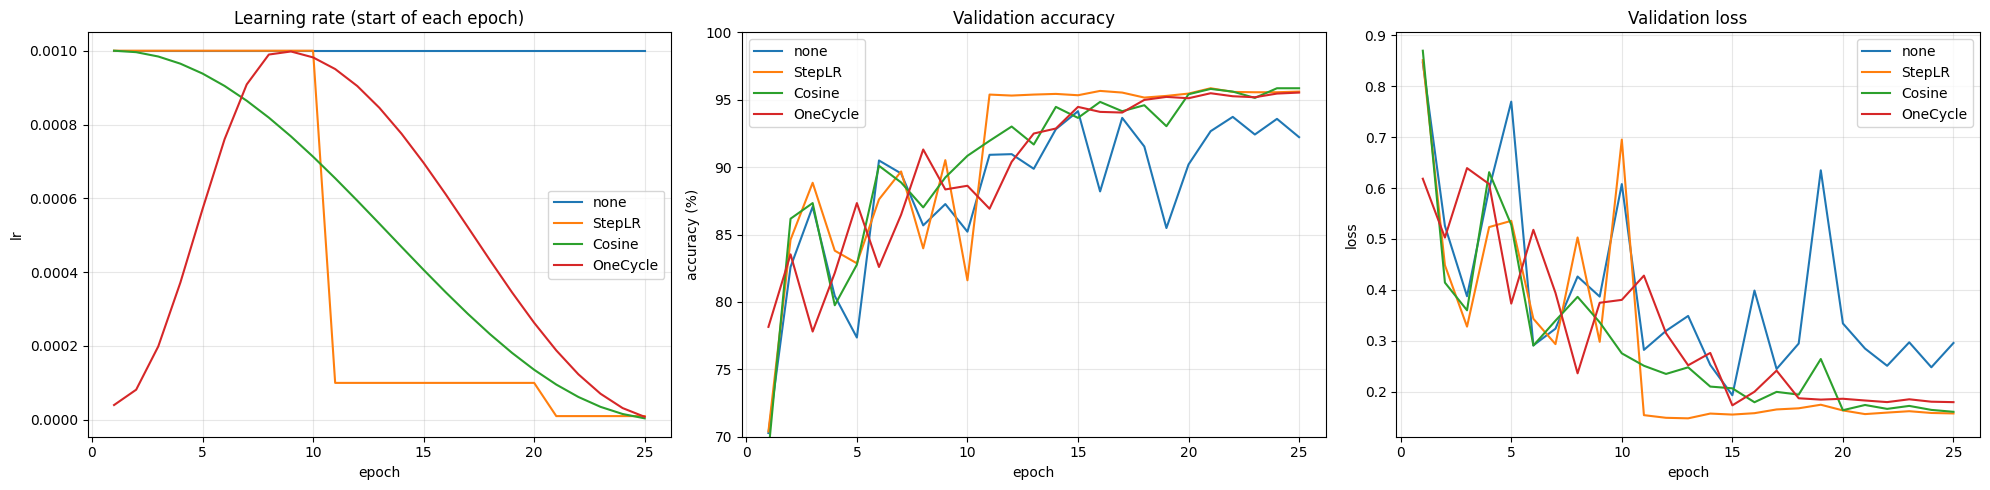

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for sched_name, name in SCHED_RUNS.items():
    h = all_histories[name]
    axes[0].plot(epochs, h["lr"], label=sched_name)
    axes[1].plot(epochs, h["val_acc"], label=sched_name)
    axes[2].plot(epochs, h["val_loss"], label=sched_name)
axes[0].set_title("Learning rate (start of each epoch)"); axes[0].set_ylabel("lr")
axes[1].set_title("Validation accuracy"); axes[1].set_ylabel("accuracy (%)"); axes[1].set_ylim(70, 100)
axes[2].set_title("Validation loss"); axes[2].set_ylabel("loss")
for ax in axes:
    ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## e. Comparative table

- **best val acc**: peak validation accuracy (the checkpoint we keep)
- **final val acc**: validation accuracy at the last epoch. A big difference with the best one means the training is unstable or overfits at the end.
- **epochs to 90%**: convergence speed
- **gap**: train accuracy − validation accuracy at the best epoch

In [14]:
print('%-26s %8s %8s %10s %13s %14s %8s %12s %12s' % ('run', 'optim', 'lr', 'scheduler', 'best val acc', 'final val acc', 'gap', 'epochs->90%', 'time (s)'))
print('-' * 120)
for name, s in all_summaries.items():
    print('%-26s %8s %8g %10s %12.2f%% %13.2f%% %8.2f %12s %12.0f' % (name, s["optimizer"], s["lr"], s["scheduler"], s["best_val_acc"],
          s["final_val_acc"], s["gen_gap"], s["epochs_to_90"] if s["epochs_to_90"] else "never", s["train_time_s"]))

with open(os.path.join(RES_DIR, "NB3_summaries.json"), "w") as f:
    json.dump({"arch": ARCH, "summaries": all_summaries, "recipes": all_recipes}, f, indent=2)

run                           optim       lr  scheduler  best val acc  final val acc      gap  epochs->90%     time (s)
------------------------------------------------------------------------------------------------------------------------
SGD_lr0.01                      SGD     0.01       none        93.28%         93.16%     5.49           10          491
SGD_lr0.001                     SGD    0.001       none        93.31%         93.21%     6.09            9          347
SGD_lr0.0001                    SGD   0.0001       none        90.52%         90.52%     2.29           23          349
Adam_lr0.01                    Adam     0.01       none        93.04%         91.60%     3.51           12          326
Adam_lr0.001                   Adam    0.001       none        94.15%         92.22%     2.47            6          341
Adam_lr0.0001                  Adam   0.0001       none        92.32%         89.41%     6.91            9          367
AdamW_lr0.01                  AdamW    

## f. Best training recipe on the test set

The best run (on the **validation** set) gives the training recipe used in NB4 (data augmentation). We evaluate its checkpoint once on the test set.

In [15]:
best_name = max(all_summaries.keys(), key=lambda n: all_summaries[n]["best_val_acc"])
best_recipe = all_recipes[best_name]
print("best run:", best_name, best_recipe)

best_net = ConfigNet(**ARCH).to(device)
best_net.load_state_dict(torch.load(os.path.join(CKPT_DIR, "NB3_%s.pth" % best_name), map_location=device))
test_loss, test_acc, test_per_class_acc, test_preds, test_labels = evaluate(best_net, testloader, criterion)
all_summaries[best_name]["test_acc"] = test_acc
all_summaries[best_name]["params"] = sum(p.numel() for p in best_net.parameters())
all_summaries[best_name]["latency_ms"] = measure_latency(best_net)

print('Accuracy of the network on the %d test images: %.2f %%' % (len(testset), test_acc))
for c in range(num_classes):
    print('Accuracy of %22s : %.1f %%' % (classes[c], test_per_class_acc[c]))

with open(os.path.join(RES_DIR, "NB3_best_recipe.json"), "w") as f:
    json.dump({"name": best_name, "arch": ARCH, "recipe": best_recipe, "n_epochs": n_epochs, "test_acc": test_acc}, f, indent=2)

best run: Adam_lr0.001_StepLR {'optimizer': 'Adam', 'lr': 0.001, 'scheduler': 'StepLR'}
Accuracy of the network on the 4050 test images: 96.22 %
Accuracy of             AnnualCrop : 94.4 %
Accuracy of                 Forest : 99.1 %
Accuracy of   HerbaceousVegetation : 96.2 %
Accuracy of                Highway : 94.9 %
Accuracy of             Industrial : 98.7 %
Accuracy of                Pasture : 95.7 %
Accuracy of          PermanentCrop : 90.1 %
Accuracy of            Residential : 98.7 %
Accuracy of                  River : 94.1 %
Accuracy of                SeaLake : 98.9 %


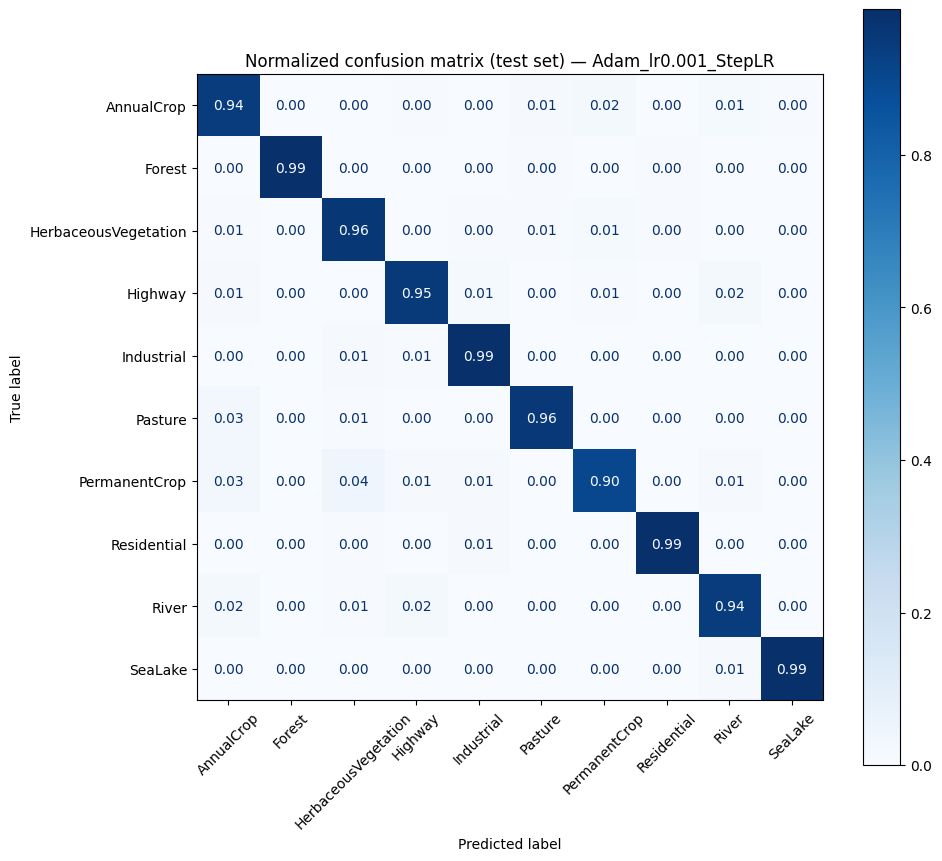

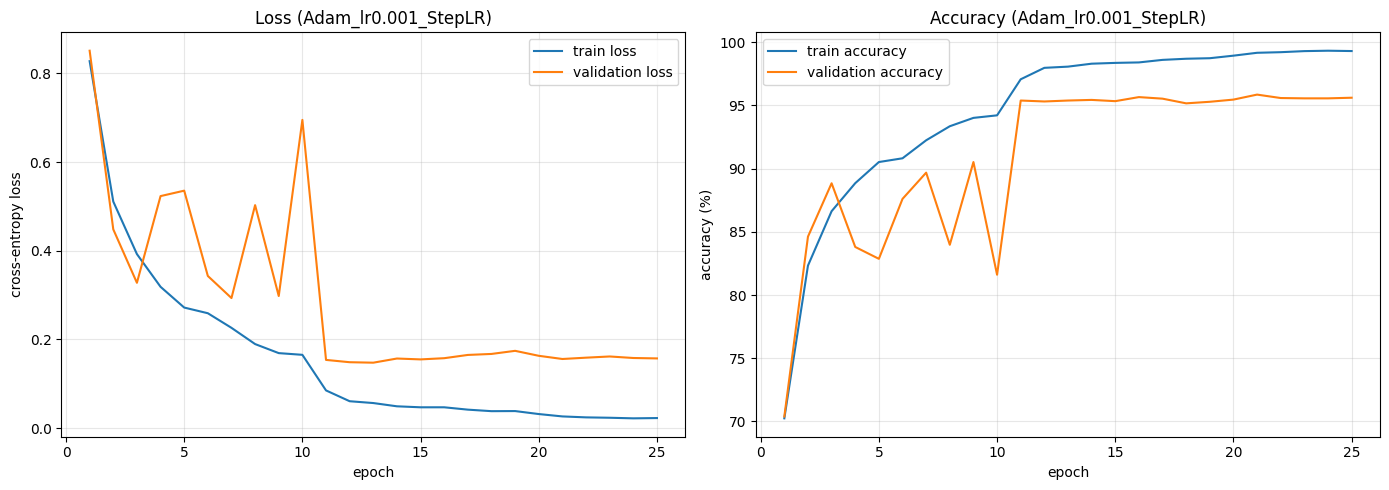

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(test_labels, test_preds, normalize="true")
fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, cmap="Blues", values_format=".2f", xticks_rotation=45)
ax.set_title("Normalized confusion matrix (test set) — %s" % best_name)
plt.tight_layout()
plt.show()

h = all_histories[best_name]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(epochs, h["train_loss"], label="train loss"); ax1.plot(epochs, h["val_loss"], label="validation loss")
ax1.set_xlabel("epoch"); ax1.set_ylabel("cross-entropy loss"); ax1.set_title("Loss (%s)" % best_name); ax1.legend(); ax1.grid(alpha=0.3)
ax2.plot(epochs, h["train_acc"], label="train accuracy"); ax2.plot(epochs, h["val_acc"], label="validation accuracy")
ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy (%)"); ax2.set_title("Accuracy (%s)" % best_name); ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## g. Load a saved checkpoint and test it on unseen mini-batches

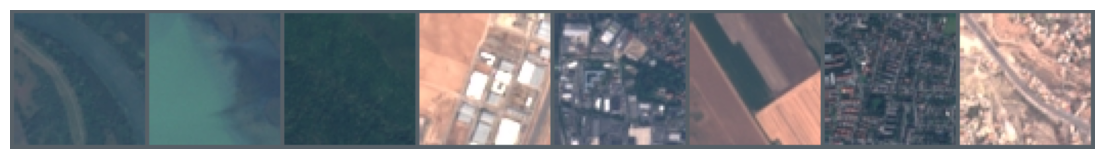

GroundTruth:  River | SeaLake | Forest | Industrial | Industrial | AnnualCrop | Residential | Highway
Predicted  :  River (1.00) | SeaLake (1.00) | Forest (1.00) | Industrial (1.00) | Industrial (1.00) | AnnualCrop (1.00) | Residential (1.00) | Highway (1.00)


In [17]:
NAME = best_name   # any run of this notebook, e.g. "Adam_lr0.01"

trainednet = ConfigNet(**ARCH)
trainednet.load_state_dict(torch.load(os.path.join(CKPT_DIR, "NB3_%s.pth" % NAME), map_location="cpu"))
trainednet.eval()

def imshow(img):
    img = img * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)
    npimg = img.clamp(0, 1).numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis("off")

demo_loader = DataLoader(testset, batch_size=8, shuffle=True)
images, labels = next(iter(demo_loader))
with torch.no_grad():
    outputs = trainednet(images)
    softmax = nn.Softmax(dim=1)
    probs = softmax(outputs)
    conf, predicted = torch.max(probs, 1)

plt.figure(figsize=(14, 3))
imshow(torchvision.utils.make_grid(images, nrow=8))
plt.show()
print('GroundTruth: ', ' | '.join('%s' % classes[labels[j]] for j in range(8)))
print('Predicted  : ', ' | '.join('%s (%.2f)' % (classes[predicted[j]], conf[j]) for j in range(8)))